# Multivariate forecasting

**When one model forecasts several series at once, a forecast can be right and still sit under the wrong name.** Think of demand at three warehouses, or three sensors on one machine. The model returns one table with a column per series, and everything downstream reads those columns by name. Mix up the names and every number is still a sensible forecast, just of the wrong series. A score that lines columns up by position won't notice.

In this notebook we forecast three related series together and break the forecast in exactly that way, to see what TimeGym does with it. Then we test a natural idea: since the series move together, a model that sees all three histories should forecast each one better. Because we generated the data, TimeGym holds the **answer key**: what a perfect forecaster that knows the true process would predict. It tells us why that idea fails here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

from timegym import GaussianAR1Forecaster, Pipeline, Scenario
from timegym.diagnostics import evaluate_forecast
from timegym.mutations import mutate_forecast

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## Three series that move together

Each series is mean reversion (AR(1)): shocks fade, and the series drifts back to its own level, 0 for `y0`, 4 for `y1` and −2 for `y2`. The three are related through their shocks: when `y0` jumps, `y1` usually jumps at the same step, and `y2` a little. The model gets 240 steps of history and must forecast the next 18; it never sees the answer key. The table shows how closely the series move together over the history.

In [2]:
scenario = Scenario(
    'ar1', context_length=240, horizon=18, n_targets=3, seed=2026,
    parameters={
        'mean': [0.0, 4.0, -2.0], 'phi': 0.75, 'sigma': [0.4, 0.9, 0.6],
        'correlation': [[1.0, 0.7, 0.2], [0.7, 1.0, 0.4], [0.2, 0.4, 1.0]],
    },
)
case = scenario.generate()
history, future_index = case.task.context, case.task.future_index
answer_key = case.reference.mean  # 18 steps x 3 series
display(history.corr().round(2))

,y0,y1,y2
y0,1.00,0.72,0.27
y1,0.72,1.00,0.45
y2,0.27,0.45,1.00


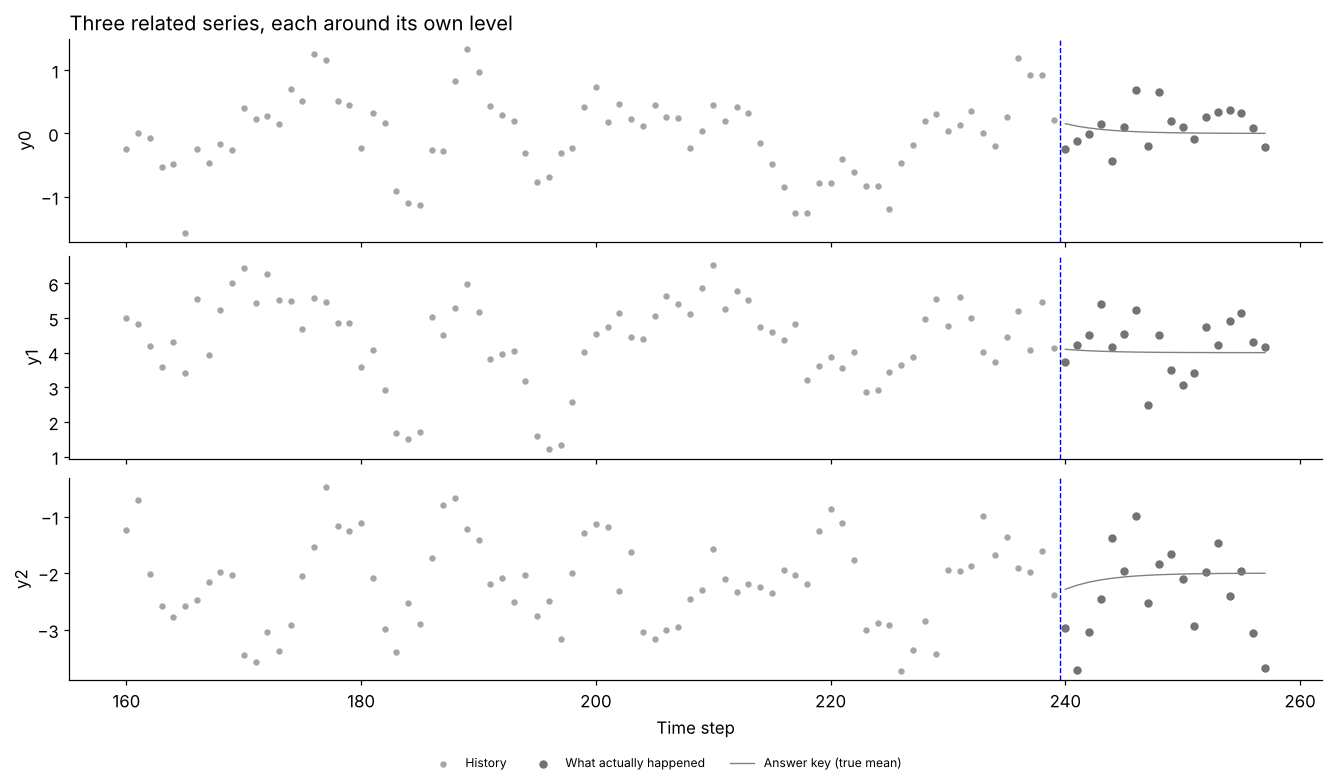

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True, layout='constrained')
for d, (name, ax) in enumerate(zip(case.task.target_names, axes)):
    ax.scatter(history.index[-80:], history[name].iloc[-80:], color='0.65', s=10, label='History')
    ax.scatter(future_index, case.observed[name], color='0.45', s=20, label='What actually happened')
    ax.plot(future_index, answer_key[:, d], color='0.5', linewidth=0.9, label='Answer key (true mean)')
    ax.axvline(future_index[0] - 0.5, color='#0000CC', linestyle='--', linewidth=0.9)
    ax.set_ylabel(name)
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=3, fontsize=8)
axes[-1].set_xlabel('Time step')
axes[0].set_title('Three related series, each around its own level')
plt.show()

Each series wanders around its own level. After the dashed line the answer key bends back toward that level: given the history, the best forecast is that today's distance from the level fades.

## One forecast for three series

We fit a mean-reversion model (`GaussianAR1Forecaster`) to the history. It learns one equation per series, in which the next value depends only on that series' own last value, plus how the three series' shocks move together. It returns one forecast for all three, with each column named after its series.

In [4]:
model = Pipeline(GaussianAR1Forecaster(n_samples=128, seed=610))
forecast = model.predict(history, future_index)
print(f'{len(forecast.index)} steps for each of {len(forecast.target_names)} series, with '
      f'{len(forecast.levels)} quantiles per step and {forecast.samples.shape[0]} sample paths.')
display(pd.DataFrame(forecast.point, index=forecast.index, columns=forecast.target_names).head(3).round(2))

18 steps for each of 3 series, with 3 quantiles per step and 128 sample paths.


,y0,y1,y2
240,0.18,4.21,-2.27
241,0.16,4.27,-2.19
242,0.15,4.31,-2.12


The column names are all that ties each column to its series.

## Right numbers, wrong series

Now the bug. Somewhere between the model and the output the series names come out reversed: the column holding `y0`'s forecast is labelled `y2`, and `y2`'s is labelled `y0`. Not one number changes. It is an easy mistake, for example when the names come from one list and the columns from another, in a different order. `mutate_forecast(forecast, 'target_swap')` makes this bug on purpose.

Anyone who reads the forecast by name now gets the wrong series. The right-hand panels show what they would see.

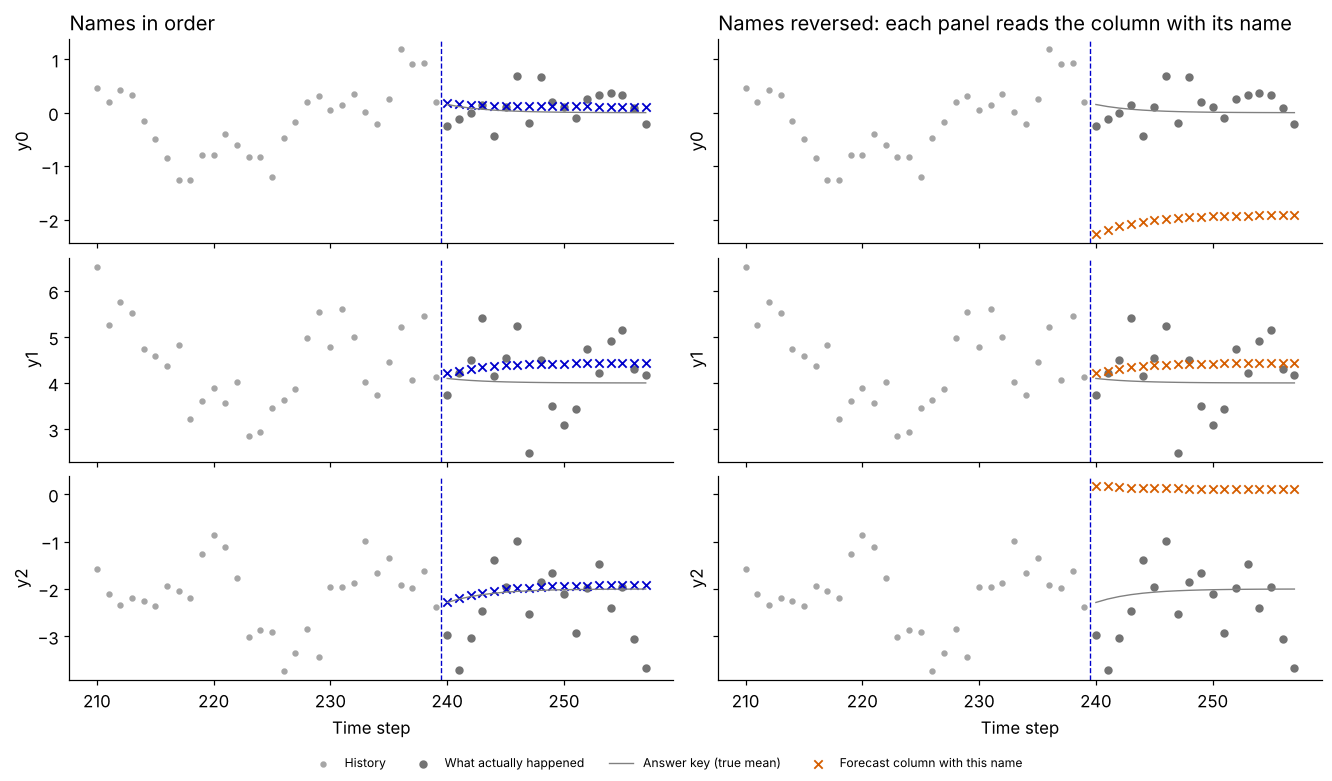

In [5]:
swapped = mutate_forecast(forecast, 'target_swap')
read_by_name = {
    'Names in order': pd.DataFrame(forecast.point, index=forecast.index, columns=forecast.target_names),
    'Names reversed': pd.DataFrame(swapped.point, index=swapped.index, columns=swapped.target_names),
}
fig, axes = plt.subplots(3, 2, figsize=(12, 7), sharex=True, sharey='row', layout='constrained')
for d, name in enumerate(case.task.target_names):
    for ax, (version, table), color in zip(axes[d], read_by_name.items(), ['#0000CC', '#D55E00']):
        ax.scatter(history.index[-30:], history[name].iloc[-30:], color='0.65', s=10, label='History')
        ax.scatter(future_index, case.observed[name], color='0.45', s=20, label='What actually happened')
        ax.plot(future_index, answer_key[:, d], color='0.5', linewidth=0.9, label='Answer key (true mean)')
        ax.scatter(future_index, table[name], marker='x', color=color, s=30, linewidths=1.2,
                   label='Forecast column with this name')
        ax.axvline(future_index[0] - 0.5, color='#0000CC', linestyle='--', linewidth=0.9)
        ax.set_ylabel(name)
axes[0, 0].set_title('Names in order')
axes[0, 1].set_title('Names reversed: each panel reads the column with its name')
axes[-1, 0].set_xlabel('Time step')
axes[-1, 1].set_xlabel('Time step')
handles, labels = axes[0, 1].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=4, fontsize=8)
plt.show()

On the left, each forecast sits on its own series, near the answer key (a little high for `y1`). On the right, the column named `y0` sits near −2, far below `y0`, and the column named `y2` sits near 0, far above `y2`. The middle column kept its name, so `y1` looks fine.

A score that lines columns up by position sees the same numbers as before, so it gives the same score. TimeGym first runs its **output checks**: right dates, every series present and in the right order, right shape, finite values, quantiles in order. Only a forecast that passes them gets scored. Below, the three versions are scored both ways. The third switches the bug off (`enabled=False`), which gives back the same forecast through the same code path.

In [6]:
versions = {'Names in order': forecast, 'Names reversed': swapped,
            'Bug switched off': mutate_forecast(forecast, 'target_swap', enabled=False)}
results = {version: evaluate_forecast(case, f) for version, f in versions.items()}
rows = []
for version, f in versions.items():
    output_check = next(d for d in results[version].diagnostics if d.category == 'correctness')
    error = results[version].metrics.get('mean_reference_mse')
    rows.append({'forecast': version,
                 'position-only error against the answer key': np.mean((f.point - answer_key) ** 2).round(3),
                 'TimeGym output checks': f'{output_check.status} ({output_check.name})',
                 'TimeGym error against the answer key': 'not scored' if error is None else round(error, 3)})
display(pd.DataFrame(rows).set_index('forecast'))

swap_check = next(d for d in results['Names reversed'].diagnostics if d.category == 'correctness')
np.testing.assert_array_equal(swapped.point, forecast.point)  # the same numbers...
assert swap_check.name == 'contract_target_mismatch' and swap_check.status == 'FAIL'  # ...under the wrong names fail,
assert results['Names reversed'].metrics == {}  # and a broken forecast gets no score.

,position-only error against the answer key,TimeGym output checks,TimeGym error against the answer key
forecast,,,
Names in order,0.051,PASS (forecast_contract),0.051
Names reversed,0.051,FAIL (contract_target_mismatch),not scored
Bug switched off,0.051,PASS (forecast_contract),0.051


By position, the reversed forecast scores exactly as well as the correct one: no number moved. TimeGym fails it on the names (`contract_target_mismatch`) and refuses to score it. With the bug switched off, the same forecast passes again, so the failure comes from the names alone.

## Does seeing the other series help?

The three series move together, so here is a natural idea: let a model see every series' recent past, not just its own, and it should forecast each one better. We test it with a linear regression (Ridge) on the last 6 values. One version sees all three series, 18 inputs in all. The other is fitted to each series on its own, with 6 inputs. Both forecast step by step, feeding their own predictions back in.

We measure each forecast's error against the answer key (`mean_reference_mse`, computed here per series because the series have different spreads), not against what actually happened. The 18 values that happened include shocks nobody could predict, which would swamp a small difference between two models. One draw of data can still mislead, so we repeat the comparison on 10 draws from the same process. The first is the draw we have been looking at.

In [7]:
def ridge():
    return Pipeline(window_length=6).add(StandardScaler()).add(Ridge(alpha=10.0))


rows = []
for seed in range(2026, 2036):
    draw = scenario.generate(seed=seed)
    past, dates, key = draw.task.context, draw.task.future_index, draw.reference.mean
    sees_all = ridge().predict(past, dates).point
    for d, name in enumerate(draw.task.target_names):
        sees_own = ridge().predict(past[[name]], dates).point[:, 0]
        rows.append({'seed': seed, 'series': name,
                     'own history only': np.mean((sees_own - key[:, d]) ** 2),
                     'all three histories': np.mean((sees_all[:, d] - key[:, d]) ** 2)})
ridge_errors = pd.DataFrame(rows)
closer = ridge_errors['all three histories'] < ridge_errors['own history only']
summary = ridge_errors.groupby('series')[['own history only', 'all three histories']].mean()
summary['draws where all three was closer'] = closer.groupby(ridge_errors['series']).sum()
display(summary.round(3))
assert (summary['all three histories'] >= summary['own history only']).all()  # extra history never helps on average

,own history only,all three histories,draws where all three was closer
series,,,
y0,0.017,0.018,5
y1,0.060,0.072,3
y2,0.028,0.055,1


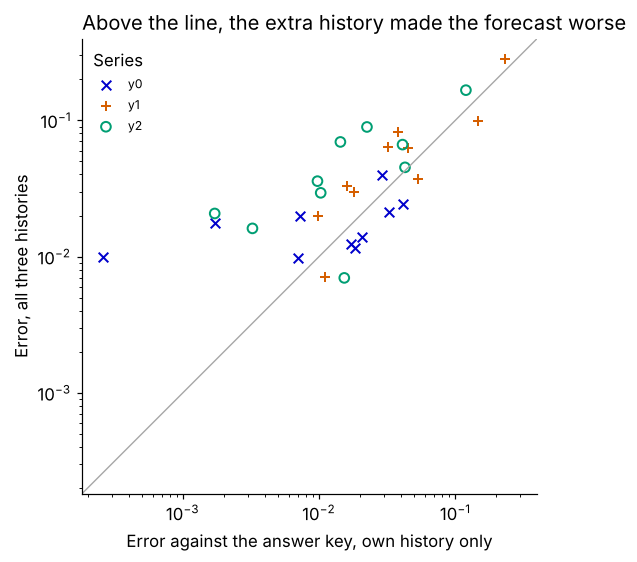

In [8]:
fig, ax = plt.subplots(figsize=(7, 5), layout='constrained')
styles = {'y0': ('#0000CC', 'x'), 'y1': ('#D55E00', '+'), 'y2': ('#009E73', 'o')}
for name, group in ridge_errors.groupby('series'):
    color, marker = styles[name]
    ax.scatter(group['own history only'], group['all three histories'], color=color, marker=marker,
               s=40, linewidths=1.3, facecolors='none' if marker == 'o' else color, label=name)
errors = ridge_errors[['own history only', 'all three histories']].to_numpy()
limits = (errors.min() * 0.7, errors.max() * 1.4)
ax.plot(limits, limits, color='0.65', linewidth=0.9)
ax.set(xscale='log', yscale='log', xlim=limits, ylim=limits, aspect='equal',
       xlabel='Error against the answer key, own history only',
       ylabel='Error, all three histories',
       title='Above the line, the extra history made the forecast worse')
ax.legend(title='Series', fontsize=8)
plt.show()

Most points sit above the line. Averaged over the 10 draws, seeing all three series makes almost no difference for `y0` and makes `y1` and `y2` worse; it came closer to the answer key in only 9 of the 30 comparisons. Three times the inputs, and no gain.

## Why the other series' history can't help here

The answer key explains it. In this process each series' next value depends only on its own last value. The series are linked only through shocks that land at the same step. Once you know `y0`'s last value, the past of `y1` and `y2` says nothing more about `y0`'s future, and the answer key ignores it. So the 12 extra inputs carry no signal, only noise for Ridge to fit.

Series that move together at the same moment are not series where one leads another (cross-series lag effects). Extra history pays off only for the second kind. On real data you can't read this off an answer key; on generated data you can.

## Change one thing

- Reverse only two names: build a `Forecast` with `target_names=('y1', 'y0', 'y2')`. The output checks still fail it.
- Set the off-diagonal correlations to 0 and rerun the Ridge comparison.
- Change the Ridge window from 6 to 12, or `alpha` from 10 to 1. Does the version that sees all three series catch up?

**What this doesn't show.** Output checks compare names, not contents: if the numbers land in the wrong columns while the names stay in order, the forecast passes them, and only its error gives it away. The Ridge result is about this process, which has no cross-series lag effects; on a process where one series leads another, the extra inputs can help. Real data has no answer key, so there you can only score against what actually happened.

**Next:** [Real-data forecasts](24_real_data_forecasts.ipynb).